In [ ]:
pip install matplotlib pandas numpy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Matplotlib version:",plt.matplotlib.__version__)
print("pandas version:",pd.__version__)

Matplotlib version: 3.10.9
pandas version: 3.0.3


### The Matplotlib Object Model

Definition

Matplotlib has two ways of plotting:

- pyplot interface (plt.plot( ... )) - quick, implicit, good for one-off scripts.
- Object-oriented (O0) interface - you explicitly create a Figure and one or more Axes, then call methods on them.

We will use the OO interface as the standard for this course, because it scales cleanly to subplots, is easier to debug, and matches how Matplotlib is used in
real codebases.

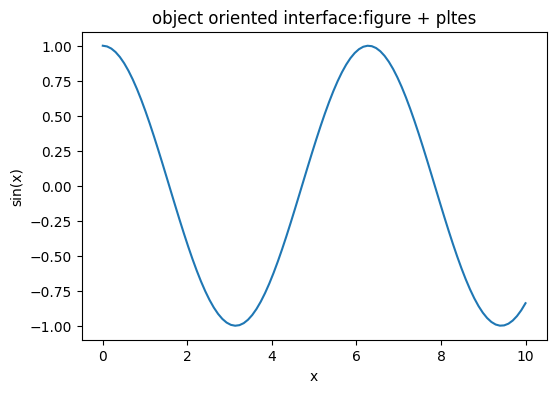

type of plt: <class 'module'>


In [ ]:
x= np.linspace(0,10,100)
y= np.cos(x)
plt.figure(figsize=(6,4))
plt.plot(x,y)
plt.title("object oriented interface:figure + pltes")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.show()

print("type of plt:",type(plt))

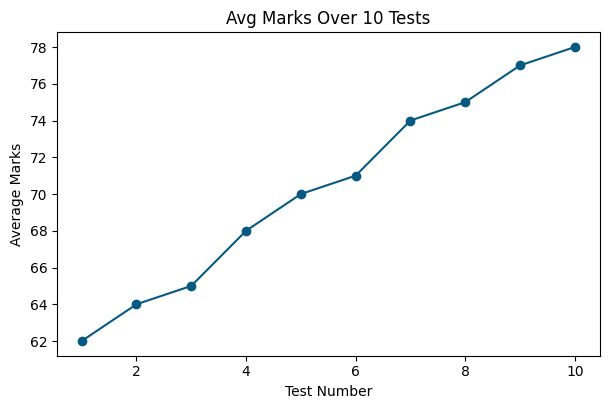

In [ ]:
days = list(range(1, 11))
avg = [62,64,65,68,70,71,74,75,77,78]

fig, ax = plt.subplots(figsize=(7,4.2))
ax.plot(days,avg,marker="o",color="#065A82")

ax.set_title("Avg Marks Over 10 Tests")
ax.set_xlabel("Test Number")
ax.set_ylabel("Average Marks")

plt.show()


# 3. Line Plots and Customisation

### Definition

`ax.plot()` draws a line plot. Common customisations:

| Parameter | Meaning |
|---|---|
| `color` | line colour (name, hex, or shorthand like `"r"`) |
| `linestyle` | `"-"`, `"--"`, `"-."`, `":"` |
| `linewidth` | thickness |
| `marker` | point marker: `"o"`, `"s"`, `"^"`, `"x"` |
| `label` | name used in the legend |

Other Axes methods you'll use constantly: `set_title`, `set_xlabel`, `set_ylabel`, `legend`, `grid`, `set_xlim` / `set_ylim`, `set_xticks`, `set_yscale`.

In [4]:
df = pd.read_csv("web_traffic_daily.csv",parse_dates=["date"])
df.head()

,date,visits,signups,page_load_ms,error_count,deployment_flag
0,2025-01-01,1258,78,218.1,2,0
1,2025-01-02,1181,52,211.0,4,0
2,2025-01-03,1292,56,219.9,1,0
3,2025-01-04,1017,52,206.6,5,0
4,2025-01-05,847,48,215.0,4,0


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date             365 non-null    datetime64[us]
 1   visits           365 non-null    int64         
 2   signups          365 non-null    int64         
 3   page_load_ms     365 non-null    float64       
 4   error_count      365 non-null    int64         
 5   deployment_flag  365 non-null    int64         
dtypes: datetime64[us](1), float64(1), int64(4)
memory usage: 17.2 KB


In [ ]:
df.dtypes

date               datetime64[us]
visits                      int64
signups                     int64
page_load_ms              float64
error_count                 int64
deployment_flag             int64
dtype: object

In [ ]:
df.shape

(365, 6)

In [ ]:
df.size

2190

In [ ]:
df.tail()

,date,visits,signups,page_load_ms,error_count,deployment_flag
360,2025-12-27,2201,136,199.3,0,0
361,2025-12-28,2237,117,210.2,3,0
362,2025-12-29,2567,144,224.3,7,0
363,2025-12-30,2447,100,213.2,1,0
364,2025-12-31,2506,103,198.2,2,0


In [ ]:
df.describe(include='all')
display( df.select_dtypes(include = "number").describe())

,visits,signups,page_load_ms,error_count,deployment_flag
count,365.000000,365.000000,365.000000,365.000000,365.000000
mean,1789.063014,88.164384,213.733699,3.583562,0.041096
std,400.581903,23.603300,35.543625,5.455288,0.198785
min,847.000000,32.000000,144.300000,0.000000,0.000000
25%,1467.000000,71.000000,199.700000,2.000000,0.000000
50%,1771.000000,85.000000,210.800000,3.000000,0.000000
75%,2117.000000,104.000000,221.400000,4.000000,0.000000
max,2567.000000,153.000000,499.400000,57.000000,1.000000


In [ ]:
print("find the how many missing values by column:")
print(df.isna().sum())
print("Total missing value in the dataSet: ")
print(df.isna().sum().sum())

find the how many missing values by column:
date               0
visits             0
signups            0
page_load_ms       0
error_count        0
deployment_flag    0
dtype: int64
Total missing value in the dataSet: 
0


### how did the number of visitors to our website change over one year?

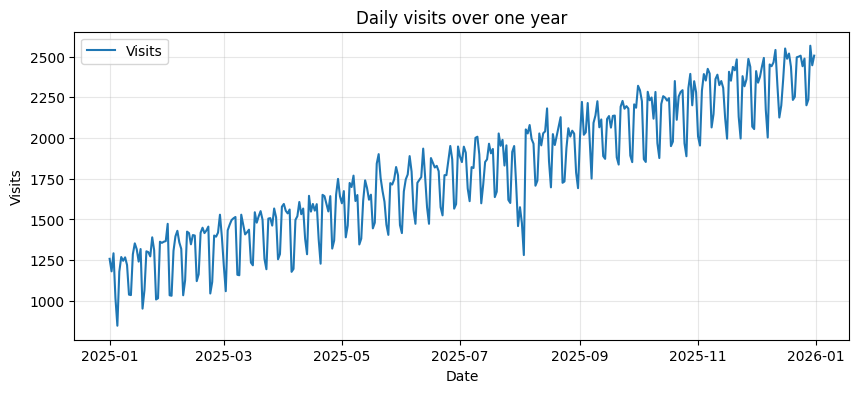

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(df["date"], df["visits"], color="tab:blue", linewidth=1.5, label="Visits")
plt.title("Daily visits over one year")
plt.xlabel("Date")
plt.ylabel("Visits")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

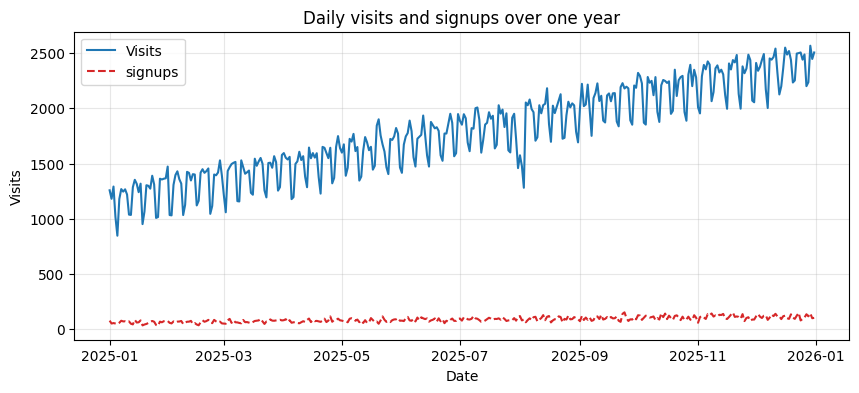

In [ ]:
# using subplots
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(df["date"],df["visits"],color="tab:blue", linewidth=1.5, label="Visits")
ax.plot(df["date"],df["signups"],color="tab:red", linewidth=1.5,linestyle="--", label="signups")
ax.set_title("Daily visits and signups over one year")
ax.set_xlabel("Date")
ax.set_ylabel("Visits")
plt.legend()
ax.grid(alpha=0.3)
plt.show()



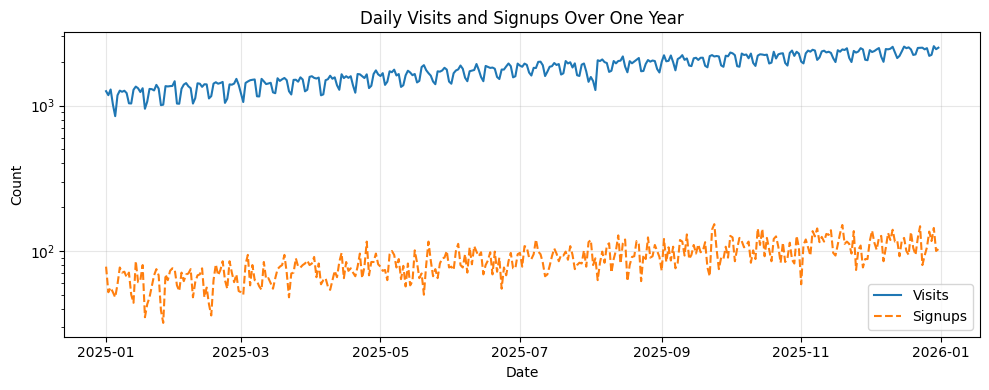

In [ ]:
# Create the figure and Axes
fig, ax = plt.subplots(figsize=(10,4))
# Plot daily visits
ax.plot(
    df["date"],
    df["visits"],
    color="tab:blue",
    linewidth=1.5,
    linestyle="-",
    label="Visits"
)
# Plot daily signups with a dashed line
ax.plot(
    df["date"],
    df["signups"],
    color="tab:orange",
    linewidth=1.5,
    linestyle="--",
    label="Signups"
)
# Add title and labels
ax.set_title("Daily Visits and Signups Over One Year")
ax.set_xlabel("Date")
ax.set_ylabel("Count")
# Use logarithmic scale on the Y-axis
ax.set_yscale("log")
ax.legend()
ax.grid(alpha=0.3)

# Display the plot
plt.tight_layout()
plt.show()

# 4. Main Plot Types

### Definition

| Chart | Use it to show | Call |
|---|---|---|
| Scatter | Relationship between two numeric variables | `ax.scatter(x, y)` |
| Bar | Comparison across categories | `ax.bar(x, height)` |
| Histogram | Distribution of one numeric variable | `ax.hist(data, bins=...)` |
| Box plot | Spread, median, outliers | `ax.boxplot(data)` |
| Pie | Share of a whole (use sparingly - see section 8) | `ax.pie(sizes)` |

### 4.1 Scatter plot

### does a slower website experience mare errors and hoe does website traffic related to these errors

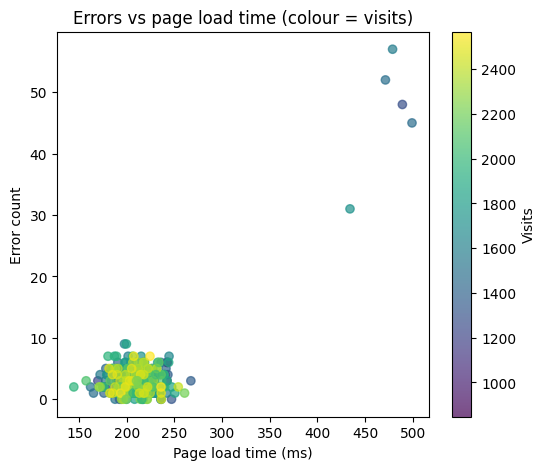

In [ ]:
plt.figure(figsize=(6, 5))
sc =plt.scatter(df["page_load_ms"], df["error_count"],
                 c=df["visits"], cmap="viridis", alpha=0.7)
plt.title("Errors vs page load time (colour = visits)")
plt.xlabel("Page load time (ms)")
plt.ylabel("Error count")
plt.colorbar(sc,label="Visits")
plt.show()


## Bar graph

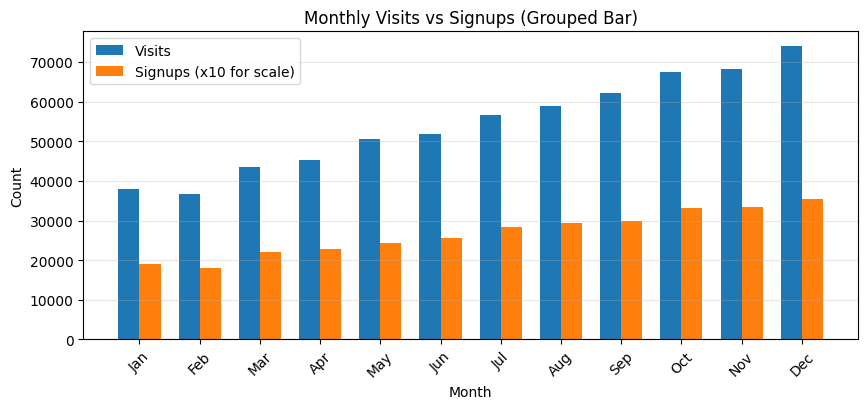

In [ ]:
monthly = df.set_index("date").resample("ME")[["visits", "signups"]].sum()
 
monthly.index = monthly.index.strftime("%b")
 
plt.figure(figsize=(10, 4))
 
x = np.arange(len(monthly))
width = 0.35
 
plt.bar(
    x - width/2,
    monthly["visits"],
    width,
    label="Visits"
)
 
plt.bar(
    x + width/2,
    monthly["signups"] * 10,
    width,
    label="Signups (x10 for scale)"
)
 
plt.xticks(x, monthly.index, rotation=45)
 
plt.title("Monthly Visits vs Signups (Grouped Bar)")
plt.xlabel("Month")
plt.ylabel("Count")
plt.legend()
plt.grid(axis="y", alpha=0.3)
 
plt.show()
 

In [ ]:
print(df)

          date  visits  signups  page_load_ms  error_count  deployment_flag
0   2025-01-01    1258       78         218.1            2                0
1   2025-01-02    1181       52         211.0            4                0
2   2025-01-03    1292       56         219.9            1                0
3   2025-01-04    1017       52         206.6            5                0
4   2025-01-05     847       48         215.0            4                0
..         ...     ...      ...           ...          ...              ...
360 2025-12-27    2201      136         199.3            0                0
361 2025-12-28    2237      117         210.2            3                0
362 2025-12-29    2567      144         224.3            7                0
363 2025-12-30    2447      100         213.2            1                0
364 2025-12-31    2506      103         198.2            2                0

[365 rows x 6 columns]


### Histogram

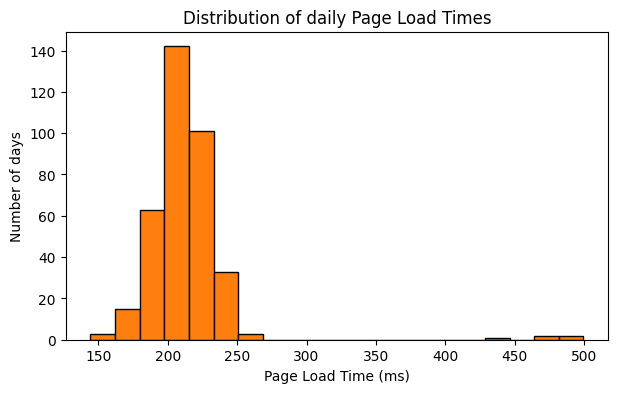

In [5]:
plt.figure(figsize=(7, 4))
plt.hist(df["page_load_ms"], bins=20, color="tab:orange", edgecolor="black")
plt.title("Distribution of daily Page Load Times")
plt.xlabel("Page Load Time (ms)")
plt.ylabel("Number of days")
plt.show()

### Box plot

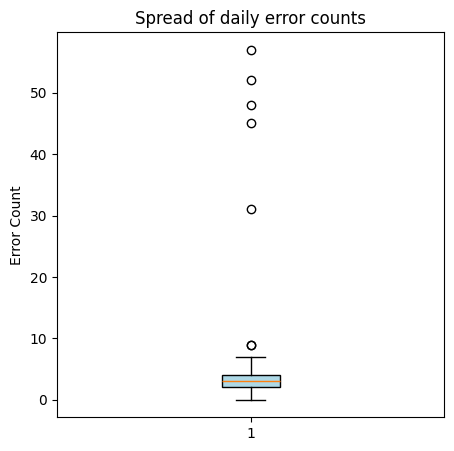

Any plot beyond the whiskers is considered a potential outlier.


In [6]:
plt.figure(figsize=(5,5))
plt.boxplot(df["error_count"],vert = True, patch_artist=True, 
            boxprops=dict(facecolor="lightblue"))
plt.title("Spread of daily error counts")
plt.ylabel("Error Count")
plt.show()
print("Any plot beyond the whiskers is considered a potential outlier.")

### PIE 


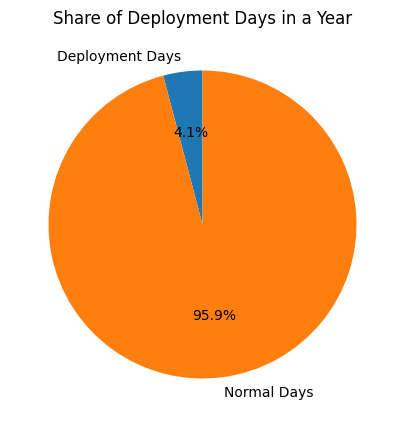

In [7]:
deploy_day= df["deployment_flag"].sum()
normal_days= len(df) - deploy_day
plt.figure(figsize=(5,5))
plt.pie([deploy_day, normal_days], 
        labels=["Deployment Days", "Normal Days"], 
        autopct="%1.1f%%", startangle=90)
plt.title("Share of Deployment Days in a Year")
plt.show()

## Subplots

defination

`plt.subplots(nrows,ncols)` returmd a figure and an array of axes,letting you place several related plot inn a grid.

useful options: `figsize, sharex,sharey,constrained_layout = true`

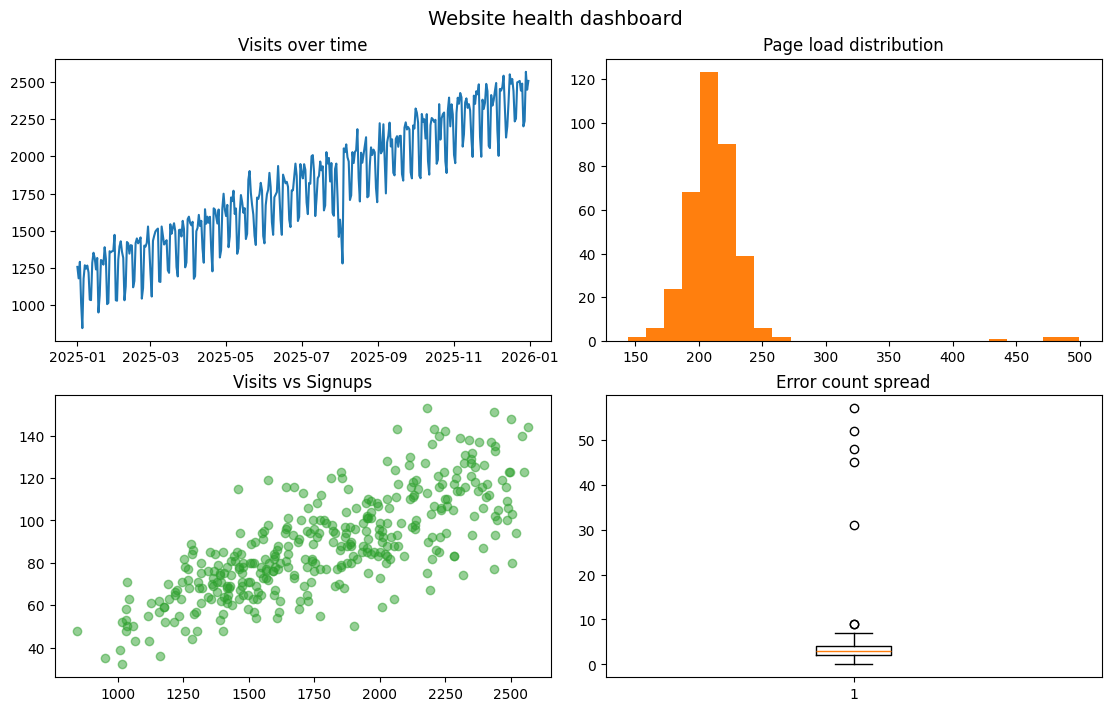

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
 
axes[0, 0].plot(df["date"], df["visits"], color="tab:blue")
axes[0, 0].set_title("Visits over time")
 
axes[0, 1].hist(df["page_load_ms"], bins=25, color="tab:orange")
axes[0, 1].set_title("Page load distribution")
 
axes[1, 0].scatter(df["visits"], df["signups"], alpha=0.5, color="tab:green")
axes[1, 0].set_title("Visits vs Signups")
 
axes[1, 1].boxplot(df["error_count"])
axes[1, 1].set_title("Error count spread")
 
fig.suptitle("Website health dashboard", fontsize=14)
plt.show()
 
# Try this: change to plt.subplots(1, 4, figsize=(18, 4)) and index axes as axes[0], axes[1], ...
 

### working with real,

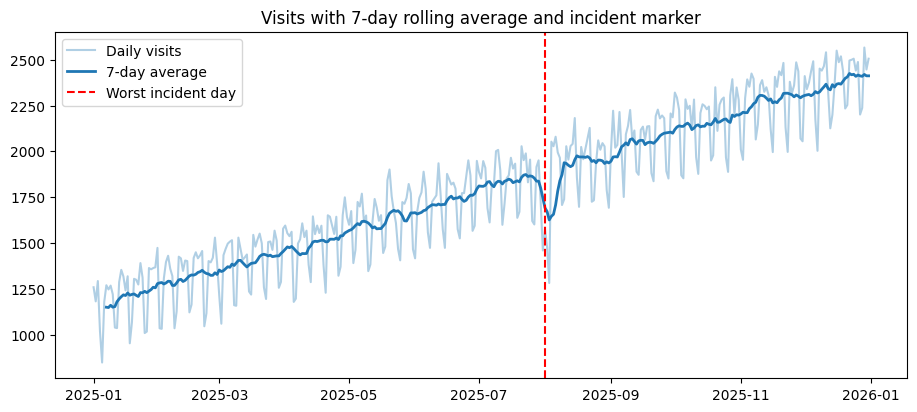

In [11]:
df["visits_7d_avg"]= df["visits"].rolling(7).mean()
incident_date = df.loc[df["error_count"].idxmax(), "date"]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(df["date"], df["visits"], alpha=0.35, label="Daily visits")
ax.plot(df["date"], df["visits_7d_avg"], color="tab:blue", linewidth=2, label="7-day average")
ax.axvline(incident_date, color="red", linestyle="--", label="Worst incident day")
ax.set_title("Visits with 7-day rolling average and incident marker")
ax.legend()
plt.show()


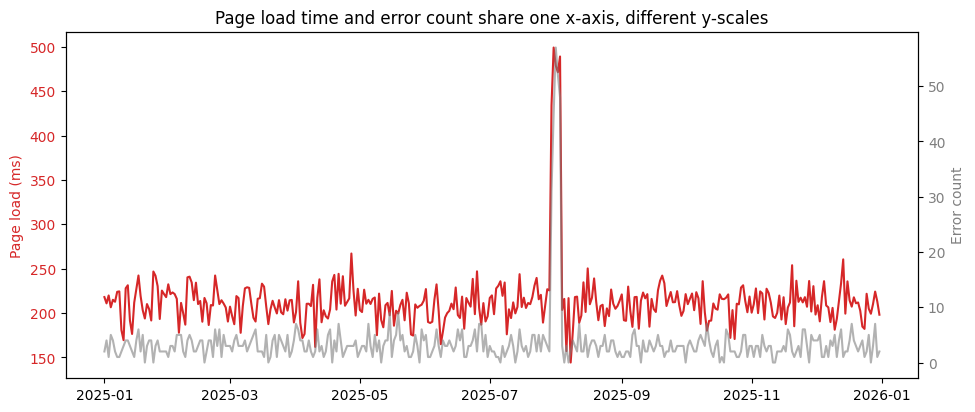

In [12]:
fig, ax1 = plt.subplots(figsize=(11, 4.5))
 
ax1.plot(df["date"], df["page_load_ms"], color="tab:red")
ax1.set_ylabel("Page load (ms)", color="tab:red")
ax1.tick_params(axis="y", labelcolor="tab:red")
 
ax2 = ax1.twinx()
ax2.plot(df["date"], df["error_count"], color="tab:gray", alpha=0.6)
ax2.set_ylabel("Error count", color="tab:gray")
ax2.tick_params(axis="y", labelcolor="tab:gray")
 
ax1.set_title("Page load time and error count share one x-axis, different y-scales")
plt.show()
 

### styles

Available styles (sample): ['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast']


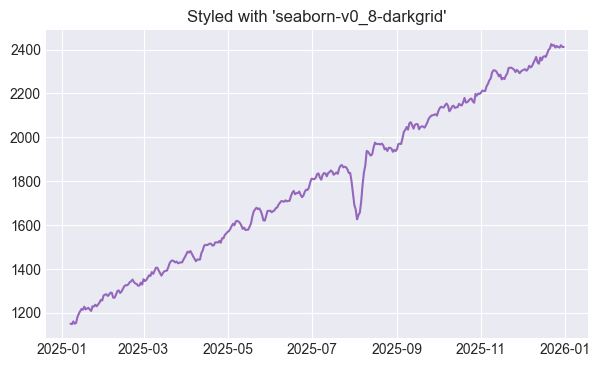

In [15]:
print("Available styles (sample):", plt.style.available[:8])

with plt.style.context("seaborn-v0_8-darkgrid"):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(df["date"], df["visits_7d_avg"], color="tab:purple")
    ax.set_title("Styled with 'seaborn-v0_8-darkgrid'")
    plt.show()
fig.savefig("C:\\Users\\nhnan\\OneDrive\\Desktop\\calibo\\visits_7d_avg_seaborn.png", dpi=300, bbox_inches="tight")